In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import plot_tree, DecisionTreeClassifier

In [2]:
wine = pd.read_csv('Dataset/white_wine.csv')
wine

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6.0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6.0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6.0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...
515,6.1,0.31,0.26,2.2,0.051,28.0,167.0,0.9926,3.37,0.47,10.4,6.0
516,6.8,0.18,0.37,1.6,0.055,47.0,154.0,0.9934,3.08,0.45,9.1,5.0
517,7.4,0.15,0.42,1.7,0.045,49.0,154.0,0.9920,3.00,0.60,10.4,6.0
518,5.9,0.13,0.28,1.9,0.050,20.0,78.0,0.9918,3.43,0.64,10.8,6.0


In [3]:
wine.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 520 entries, 0 to 519
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         520 non-null    float64
 1   volatile acidity      520 non-null    float64
 2   citric acid           520 non-null    float64
 3   residual sugar        520 non-null    float64
 4   chlorides             520 non-null    float64
 5   free sulfur dioxide   520 non-null    float64
 6   total sulfur dioxide  520 non-null    float64
 7   density               520 non-null    float64
 8   pH                    519 non-null    float64
 9   sulphates             519 non-null    float64
 10  alcohol               519 non-null    float64
 11  quality               519 non-null    float64
dtypes: float64(12)
memory usage: 48.9 KB


In [34]:
# describe
wine.describe().loc[['mean','min','max']].T

,mean,min,max
fixed acidity,6.812115,5.0000,10.2000
volatile acidity,0.289260,0.1000,0.9050
citric acid,0.338327,0.0000,0.8800
residual sugar,6.624615,0.8000,22.0000
chlorides,0.047781,0.0200,0.3460
free sulfur dioxide,37.146154,3.0000,131.0000
total sulfur dioxide,146.545192,41.0000,313.0000
density,0.995374,0.9899,1.0033
pH,3.210289,2.8700,3.7200
sulphates,0.486936,0.2700,0.8500


In [5]:
# set the quality as the target, if quality > 6, change it to 1, else 0
wine['label'] = np.where(wine['quality']>6 , 1, 0)
wine

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,label
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6.0,0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6.0,0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6.0,0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0,0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
515,6.1,0.31,0.26,2.2,0.051,28.0,167.0,0.9926,3.37,0.47,10.4,6.0,0
516,6.8,0.18,0.37,1.6,0.055,47.0,154.0,0.9934,3.08,0.45,9.1,5.0,0
517,7.4,0.15,0.42,1.7,0.045,49.0,154.0,0.9920,3.00,0.60,10.4,6.0,0
518,5.9,0.13,0.28,1.9,0.050,20.0,78.0,0.9918,3.43,0.64,10.8,6.0,0


In [6]:
wine['label'].value_counts(normalize=True)

label
0    0.811538
1    0.188462
Name: proportion, dtype: float64

In [7]:
# check the value
wine['label'].value_counts()

label
0    422
1     98
Name: count, dtype: int64

<Axes: xlabel='density', ylabel='alcohol'>

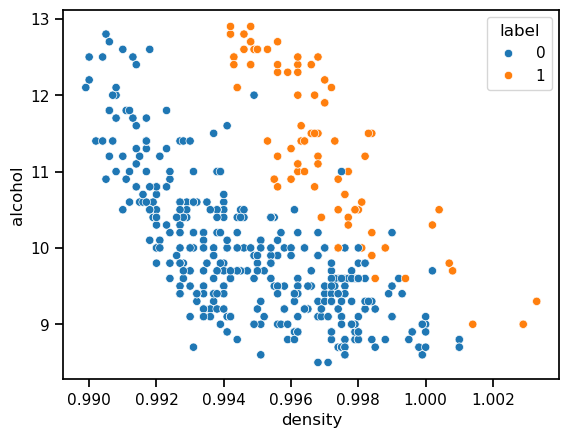

In [8]:
# let's take a look for the scatter visualization
sns.set_context('notebook', font_scale=1)
sns.scatterplot(data=wine, x='density', y='alcohol', hue='label')

In [9]:
# last time, we see null value, fill the null value
wine[['density', 'alcohol']].isnull().sum()

density    0
alcohol    1
dtype: int64

In [10]:
# quick handle, it's only 1 data point, fill it with median
wine['alcohol'].fillna(wine['alcohol'].median(), inplace=True)

# and check again
wine[['density', 'alcohol']].isnull().sum()

density    0
alcohol    0
dtype: int64

In [11]:
# define feature and target
x = wine[['density', 'alcohol']]
y = wine[['label']]
display(x,y)

,density,alcohol
0,1.0010,8.8
1,0.9940,9.5
2,0.9951,10.1
3,0.9956,9.9
4,0.9956,9.9
...,...,...
515,0.9926,10.4
516,0.9934,9.1
517,0.9920,10.4
518,0.9918,10.8


,label
0,0
1,0
2,0
3,0
4,0
...,...
515,0
516,0
517,0
518,0


In [23]:
# feature selection
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    stratify=y,
    random_state=42
)

In [24]:
# let's define the model
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(x_train, y_train)
y_predict_class = knn.predict(x_test)

c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [25]:
print(f'the model accuracy on data test is: ', accuracy_score(y_test, y_predict_class))

the model accuracy on data test is:  0.9230769230769231


In [26]:
# implementing the min_max scaler
from sklearn.preprocessing import MinMaxScaler

scale = MinMaxScaler()
scale.fit(x_train) # preprocessing for scaling
x_train_scaled = scale.transform(x_train)
x_test_scaled = scale.transform(x_test)
display(x_train_scaled)


array([[0.06716418, 0.56818182],
       [0.30597015, 0.20454545],
       [0.42537313, 0.95454545],
       [0.3358209 , 0.27272727],
       [0.13432836, 0.65909091],
       [0.04477612, 0.97727273],
       [0.41044776, 0.43181818],
       [0.41044776, 0.29545455],
       [0.40298507, 0.93181818],
       [0.36567164, 1.        ],
       [0.18656716, 0.25      ],
       [0.55970149, 0.15909091],
       [0.51492537, 0.13636364],
       [0.05223881, 0.95454545],
       [0.28358209, 0.25      ],
       [0.59701493, 0.11363636],
       [0.26119403, 0.38636364],
       [0.48507463, 0.56818182],
       [0.64179104, 0.04545455],
       [0.42537313, 0.86363636],
       [0.24626866, 0.47727273],
       [0.58208955, 0.56818182],
       [0.32835821, 0.88636364],
       [0.20895522, 0.45454545],
       [0.59701493, 0.45454545],
       [0.37313433, 0.25      ],
       [0.58955224, 0.11363636],
       [0.57462687, 0.22727273],
       [0.54477612, 0.09090909],
       [0.11940299, 0.47727273],
       [0.

In [27]:
# let's do the model fitting
knn = KNeighborsClassifier(n_neighbors=3)
knn = knn.fit(x_train_scaled, y_train)
y_predict_class = knn.predict(x_test_scaled)

c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [28]:
print(f'the model accuracy on data test after scaled is: ', accuracy_score(y_test, y_predict_class))

the model accuracy on data test after scaled is:  0.9846153846153847


In [29]:
# create iterations for comparing the training accuracy and test accuracy
k = np.arange(1,30,2)
training_accuracies = []
test_accuracies = []
score = 0

for i in k:
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(x_train_scaled, y_train)
    
    y_predict_train = knn.predict(x_train_scaled)
    training_accuracies.append(accuracy_score(y_train, y_predict_train))
    
    y_predict_test = knn.predict(x_test_scaled)
    acc_score = accuracy_score(y_test, y_predict_test)
    test_accuracies.append(acc_score)
    
    if score < acc_score:
        score = acc_score
        best_k = i

c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
c:\Users\asus\anaconda3\Lib\site-packages\sklearn\neighbors\_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples

In [30]:
df_k = pd.DataFrame(k, columns=['k'])
df_k['training_accuracy'] = pd.DataFrame(training_accuracies, columns=['temp'])
df_k['test_accuracy'] = pd.DataFrame(test_accuracies, columns=['temp'])
df_k

,k,training_accuracy,test_accuracy
0,1,0.997436,0.984615
1,3,0.979487,0.984615
2,5,0.974359,0.984615
3,7,0.966667,0.992308
4,9,0.964103,0.969231
5,11,0.966667,0.953846
6,13,0.958974,0.946154
7,15,0.958974,0.953846
8,17,0.961538,0.969231
9,19,0.958974,0.953846


In [31]:
# pd.melt
df_melted = pd.melt(df_k,id_vars=['k'],value_vars=['training_accuracy','test_accuracy'],var_name='attribute',value_name='value')
df_melted

,k,attribute,value
0,1,training_accuracy,0.997436
1,3,training_accuracy,0.979487
2,5,training_accuracy,0.974359
3,7,training_accuracy,0.966667
4,9,training_accuracy,0.964103
5,11,training_accuracy,0.966667
6,13,training_accuracy,0.958974
7,15,training_accuracy,0.958974
8,17,training_accuracy,0.961538
9,19,training_accuracy,0.958974


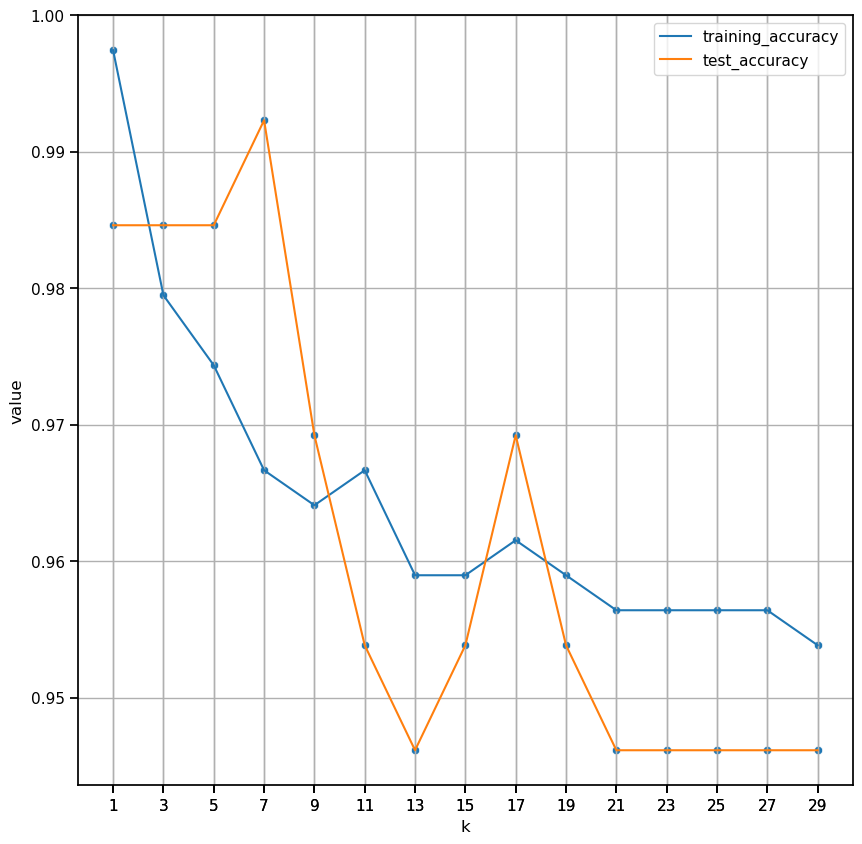

In [32]:
# plot the 2 lines
import matplotlib.pyplot as plt
plt.figure(figsize=(10,10))
sns.set_context('notebook', font_scale=1)
ax = sns.lineplot(data=df_melted, x='k', y='value', hue='attribute')
sns.scatterplot(data=df_melted, x='k', y='value')
ax.set_xticks(df_melted['k'])
plt.grid()

In [33]:
print('best k:', best_k)
print('best accuracy:', score)

best k: 7
best accuracy: 0.9923076923076923
